In [1]:
import pandas as pd
df = pd.read_csv("kharabi_system.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [3]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


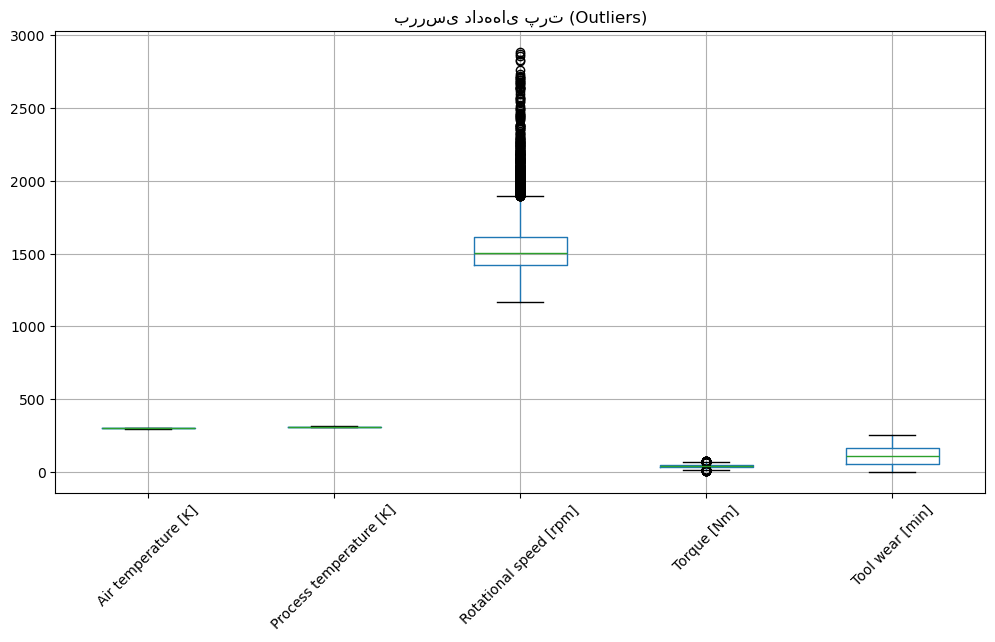

In [4]:
import matplotlib.pyplot as plt 

# کشیدن نمودار برای ستون‌های عددی
df[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']].boxplot(figsize=(12, 6), rot=45)
plt.title('بررسی داده‌های پرت (Outliers)')
plt.show()

In [5]:
df["Product ID"].unique()

array(['M14860', 'L47181', 'L47182', ..., 'M24857', 'H39412', 'M24859'],
      shape=(10000,), dtype=object)

In [6]:
df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64

In [7]:
df = df.drop(columns=['UDI', 'Product ID', 'Failure Type'])
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [8]:
# تبدیل ستون Type به عدد
df['Type'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})

# بررسی نتیجه
print(df.head())
print("\n--- نوع داده‌ها ---")
print(df.dtypes)

   Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0     1                298.1                    308.6                    1551   
1     0                298.2                    308.7                    1408   
2     0                298.1                    308.5                    1498   
3     0                298.2                    308.6                    1433   
4     0                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  Target  
0         42.8                0       0  
1         46.3                3       0  
2         49.4                5       0  
3         39.5                7       0  
4         40.0                9       0  

--- نوع داده‌ها ---
Type                         int64
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Target                       i

In [9]:
# X = ویژگی‌ها (همه ستون‌ها به جز Target)
X = df.drop(columns=['Target'])

# y = متغیر هدف (ستون Target)
y = df['Target']

print("شکل X:", X.shape)
print("شکل y:", y.shape)
print("\nستون‌های X:")
print(X.columns.tolist())

شکل X: (10000, 6)
شکل y: (10000,)

ستون‌های X:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# ۱. ساخت مدل
lr = LogisticRegression(max_iter=1000, random_state=42)
# ۲. آموزش
lr.fit(X_train, y_train)
# ۳. پیش‌بینی
y_pred_lr = lr.predict(X_test)

# ارزیابی
print("=== مدل Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

=== مدل Logistic Regression ===
Accuracy: 0.974
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1939
           1       0.67      0.30      0.41        61

    accuracy                           0.97      2000
   macro avg       0.82      0.65      0.70      2000
weighted avg       0.97      0.97      0.97      2000



In [12]:
from sklearn.tree import DecisionTreeClassifier

# ساخت و آموزش مدل
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# پیش‌بینی
y_pred_dt = dt_model.predict(X_test)

# ارزیابی
print("=== Decision Tree ===")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nclassification_report:")
print(classification_report(y_test, y_pred_dt))

=== Decision Tree ===
Accuracy: 0.9775

classification_report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1939
           1       0.61      0.74      0.67        61

    accuracy                           0.98      2000
   macro avg       0.80      0.86      0.83      2000
weighted avg       0.98      0.98      0.98      2000



In [13]:
from sklearn.ensemble import RandomForestClassifier

# ۱. ساخت مدل
rf = RandomForestClassifier(n_estimators=100, random_state=42)
# ۲. آموزش
rf.fit(X_train, y_train)
# ۳. پیش‌بینی
y_pred_rf = rf.predict(X_test)

# ارزیابی
print("=== مدل Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

=== مدل Random Forest ===
Accuracy: 0.9845
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1939
           1       0.86      0.59      0.70        61

    accuracy                           0.98      2000
   macro avg       0.92      0.79      0.85      2000
weighted avg       0.98      0.98      0.98      2000



In [14]:
from sklearn.metrics import accuracy_score, classification_report

print("--- ارزیابی Logistic Regression ---")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

print("\n--- ارزیابی Random Forest ---")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

--- ارزیابی Logistic Regression ---
Accuracy: 0.974
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1939
           1       0.67      0.30      0.41        61

    accuracy                           0.97      2000
   macro avg       0.82      0.65      0.70      2000
weighted avg       0.97      0.97      0.97      2000


--- ارزیابی Random Forest ---
Accuracy: 0.9845
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1939
           1       0.86      0.59      0.70        61

    accuracy                           0.98      2000
   macro avg       0.92      0.79      0.85      2000
weighted avg       0.98      0.98      0.98      2000



In [ ]:
import pandas as pd

print("=== سیستم پیش‌بینی خرابی دستگاه ===")
print("لطفاً مشخصات دستگاه را وارد کنید:\n")

# گرفتن ورودی از کاربر
type_input = int(input("نوع محصول (0=L, 1=M, 2=H): "))
air_temp = float(input("دمای محیط (مثلاً 300): "))
process_temp = float(input("دمای فرآیند (مثلاً 310): "))
rot_speed = float(input("سرعت چرخش (مثلاً 1500): "))
torque = float(input("گشتاور (مثلاً 40): "))
tool_wear = float(input("میزان استهلاک ابزار (مثلاً 100): "))

# ساختن دیتافریم از ورودی‌های کاربر
user_data = pd.DataFrame({
    'Type': [type_input],
    'Air temperature [K]': [air_temp],
    'Process temperature [K]': [process_temp],
    'Rotational speed [rpm]': [rot_speed],
    'Torque [Nm]': [torque],
    'Tool wear [min]': [tool_wear]
})

print("\nدر حال پردازش توسط مدل...")

# پیش‌بینی با مدل Random Forest
prediction = rf.predict(user_data)

# چاپ نتیجه نهایی
print("\n=== نتیجه ===")
if prediction[0] == 1:
    print(" هشدار: دستگاه احتمال خرابی دارد! (Target = 1)")
else:
    print(" دستگاه سالم است. (Target = 0)")

=== سیستم پیش‌بینی خرابی دستگاه ===
لطفاً مشخصات دستگاه را وارد کنید:


در حال پردازش توسط مدل...

=== نتیجه ===
✅ دستگاه سالم است. (Target = 0)
